# Linear regression: variance and bootstrap

Compare exact finite-sample variances with bootstrap estimates for averaged stochastic gradient descent.

## Settings

Choose `smoke`, `standard` or `large` for 8, 128 or 1024 datasets. Each standard or large run uses 256 bootstrap replicas. The seed is fixed. Run the cells in order; dependencies are `numpy scipy pandas matplotlib numba ipykernel`.

In [1]:
import os, sys, json, platform, time, hashlib
from pathlib import Path
os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.mplconfig'))
os.environ.setdefault('XDG_CACHE_HOME', str(Path.cwd() / '.cache'))
import numpy as np
import pandas as pd
import scipy
from scipy.stats import norm, t as student_t
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import numba
from numba import njit

PROFILE = 'standard'  # 'smoke', 'standard', 'large'
PROFILES = {'smoke': (8, 64), 'standard': (128, 256), 'large': (1024, 256)}
R, K = PROFILES[PROFILE]
SEED = 20261122
D, SIGMA, K0, BURN, OFFSET = 5, 0.02, 20000, 100, 1
GAMMAS = np.array([0.50, 0.70, 0.75, 0.85, 0.90, 0.95])
C0S = np.array([10., 200., 200., 200., 200., 200.])
CHECKPOINTS = np.array([10000, 20000, 30000, 40000, 50000], dtype=np.int64)
LONG_MAX = 10_000_000
THETA_STAR = np.array([1., 1., -.1, -.1, -.1])
u = np.random.default_rng(np.random.SeedSequence([SEED, 1])).uniform(-1, 1, D)
u /= np.linalg.norm(u)
Z = norm.ppf(.975)
OUT = Path.cwd() / 'lsa_results'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.grid': True,
                     'grid.alpha': .22, 'savefig.bbox': 'tight'})
COLORS = plt.cm.viridis(np.linspace(.05, .95, len(GAMMAS)))

def savefig(fig, name):
    fig.savefig(OUT / (name + '.pdf'))
    fig.savefig(OUT / (name + '.png'), dpi=180)
    plt.show()
    plt.close(fig)

print(f'Profile={PROFILE}; independent datasets R={R}; bootstrap replicas K={K}')
print('Projection:', u)

Profile=standard; independent datasets R=128; bootstrap replicas K=256
Projection: [ 0.59527641 -0.27613522  0.55183535  0.23000297 -0.46040387]


## Asymptotic variance

Compute $\Sigma_\infty=0.0012I_5$ for uniform features and Gaussian observation noise. This gives the reference variance for each unit projection.

In [2]:
ABAR = (2 / 3) * np.eye(D)
SIGMA_EPS = (4 * SIGMA**2 / 3) * np.eye(D)
SIGMA_INF = np.linalg.solve(ABAR, np.linalg.solve(ABAR, SIGMA_EPS).T).T
S_INF = float(u @ SIGMA_INF @ u)
assert np.allclose(SIGMA_INF, 3 * SIGMA**2 * np.eye(D))
assert np.allclose(ABAR.T + ABAR, (4 / 3) * np.eye(D))
m50 = CHECKPOINTS[-1] - BURN + 1
print('Sigma_inf ='); print(SIGMA_INF)
print('u^T Sigma_inf u =', S_INF)
print(f'95% asymptotic length at N=50000, m={m50}: {2*Z*np.sqrt(S_INF/m50):.9f}')

Sigma_inf =
[[0.0012 0.     0.     0.     0.    ]
 [0.     0.0012 0.     0.     0.    ]
 [0.     0.     0.0012 0.     0.    ]
 [0.     0.     0.     0.0012 0.    ]
 [0.     0.     0.     0.     0.0012]]
u^T Sigma_inf u = 0.0012000000000000003
95% asymptotic length at N=50000, m=49901: 0.000607875


## Exact finite-sample variances

Use second-moment recursions to calculate the linear, full-estimator and expected conditional bootstrap covariances. Divide by the asymptotic covariance to compare their sizes.

### Averaging window

Average iterates $100,\ldots,N$, giving $m=N-99$ terms. Updates use $\alpha_t=c_0/(k_0+t+1)^\gamma$. All trajectories start at the true parameter. The $\gamma=0.50$ setting uses $c_0=10$; the others use $c_0=200$.

In [3]:
@njit
def exact_moments(gamma, c0, checkpoints, burn, offset, d, sigma, k0):
    # Columns: linear, full-estimator, expected conditional bootstrap covariance.
    ans = np.zeros((len(checkpoints), 3))
    v, c, s = np.zeros(3), np.zeros(3), np.zeros(3)
    h = 1/5 + (d-1)/9
    j = 0
    for t in range(1, checkpoints[-1]+1):
        a = c0 / (k0 + t + offset)**gamma
        r, q = 1-2*a/3, 4*sigma*sigma*a*a/3
        v[0] = r*r*v[0] + q
        v[1] = (1-4*a/3+4*h*a*a)*v[1] + q
        v[2] = (1-4*a/3+8*h*a*a)*v[2] + 2*q
        if t >= burn:
            for z in range(3):
                s[z] += 2*r*c[z] + v[z]
                c[z] = r*c[z] + v[z]
        if t == checkpoints[j]:
            m = t-burn+1
            ans[j, 0] = s[0]/m
            ans[j, 1] = s[1]/m
            ans[j, 2] = (s[2]-s[1])/m
            j += 1
            if j == len(checkpoints):
                break
    return ans

def exact_grid(checkpoints, burn=BURN, offset=OFFSET):
    checkpoints = np.asarray(checkpoints, dtype=np.int64)
    assert np.all(np.diff(checkpoints)>0) and checkpoints[0]>=max(1,burn)
    rows = []
    for g, c0 in zip(GAMMAS, C0S):
        val = exact_moments(g,c0,checkpoints,burn,offset,D,SIGMA,K0)
        for N, (lin, true, boot) in zip(checkpoints,val):
            m = int(N-burn+1)
            rows.append(dict(gamma=g,c0=c0,N=int(N),m=m,
                             linear=lin,true=true,bootstrap_exact=boot,
                             linear_ratio=lin/S_INF,true_ratio=true/S_INF,
                             bootstrap_ratio=boot/S_INF,
                             length_asym=2*Z*np.sqrt(S_INF/m),
                             length_true_normal=2*Z*np.sqrt(true/m),
                             length_boot_rms_normal=2*Z*np.sqrt(boot/m)))
    return pd.DataFrame(rows)

exact = exact_grid(CHECKPOINTS)
exact.to_csv(OUT/'exact_covariances.csv', index=False)
display(exact[exact.N==50000][['gamma','c0','linear_ratio','true_ratio','bootstrap_ratio',
                              'length_asym','length_true_normal','length_boot_rms_normal']].round(9))

,gamma,c0,linear_ratio,true_ratio,bootstrap_ratio,length_asym,length_true_normal,length_boot_rms_normal
4,0.50,10.0,0.999768,1.087166,1.346312,0.000608,0.000634,0.000705
9,0.70,200.0,0.999964,1.252709,2.507991,0.000608,0.000680,0.000963
14,0.75,200.0,0.999953,1.131133,1.574628,0.000608,0.000647,0.000763
19,0.85,200.0,0.999970,1.041084,1.151102,0.000608,0.000620,0.000652
24,0.90,200.0,1.000034,1.023809,1.084760,0.000608,0.000615,0.000633
29,0.95,200.0,1.000149,1.014040,1.048795,0.000608,0.000612,0.000623


## Numerical checks

Check the scalar moment recursions against direct coefficient sums and full matrix calculations.

In [4]:
def direct_linear_variance(N, gamma, c0, burn, offset):
    # Scalar Q_l for sum of J_burn,...,J_N, retaining innovations before burn.
    a = c0/(K0+np.arange(1,N+1)+offset)**gamma
    total = 0.
    for ell in range(1,N+1):
        product, weight = 1., 0.
        for t in range(ell,N+1):
            if t>ell:
                product *= 1-2*a[t-1]/3
            if t>=burn:
                weight += a[ell-1]*product
        total += (4*SIGMA**2/3)*weight**2
    return total/(N-burn+1)

def full_matrix_sum_cov(N,gamma,c0,burn,offset,mult_second):
    # E[xx^T M xx^T] = (M+M^T+tr(M)I)/9 - (2/15)diag(diag(M)).
    I = np.eye(D)
    M, Cmat, Smat = np.zeros((D,D)), np.zeros((D,D)), np.zeros((D,D))
    for t in range(1,N+1):
        a = c0/(K0+t+offset)**gamma
        EXMX = (M+M.T+np.trace(M)*I)/9-(2/15)*np.diag(np.diag(M))
        M = (1-4*a/3)*M + 4*a*a*mult_second*EXMX + 4*a*a*mult_second*SIGMA**2/3*I
        if t>=burn:
            r = 1-2*a/3
            Smat = Smat+r*(Cmat+Cmat.T)+M
            Cmat = r*Cmat+M
    return Smat/(N-burn+1)

for b in [0, 1, 7]:
    N=31
    val=exact_moments(.85,200.,np.array([N]),b,1,D,SIGMA,K0)[0]
    assert np.isclose(val[0],direct_linear_variance(N,.85,200.,b,1),rtol=1e-11)
    V=full_matrix_sum_cov(N,.85,200.,b,1,1.)
    U=full_matrix_sum_cov(N,.85,200.,b,1,2.)
    assert np.allclose(V,val[1]*np.eye(D),rtol=1e-11,atol=1e-16)
    assert np.allclose(U-V,val[2]*np.eye(D),rtol=1e-11,atol=1e-16)
print('Direct Q_l calculation and full matrix moment checks passed.')

Direct Q_l calculation and full matrix moment checks passed.


## Bootstrap simulation

Generate independent datasets and run the estimator with bootstrap replicas. Reuse data, multipliers and the projection across step-size exponents. Record covariance estimates, interval lengths and coverage at each sample size.

In [5]:
@njit
def beta22_weights(k):
    w=np.empty(k)
    for b in range(k):
        while True:
            p=np.random.random()
            if np.random.random() <= 4*p*(1-p):
                w[b]=1+np.sqrt(20.)*(p-.5)
                break
    return w

@njit
def update_errors(state, x, eta, alphas, weights):
    # state[g,0,:] is original; state[g,1:,:] are bootstrap replicas.
    for g in range(state.shape[0]):
        for b in range(state.shape[1]):
            residual=-eta
            for j in range(state.shape[2]):
                residual += state[g,b,j]*x[j]
            mult=1. if b==0 else weights[b-1]
            step=2*alphas[g]*mult*residual
            for j in range(state.shape[2]):
                state[g,b,j] -= step*x[j]

@njit
def simulate_dataset(X, noise, alphas, checkpoints, burn, k, weight_seed):
    np.random.seed(weight_seed)
    ng,d=alphas.shape[0],X.shape[1]
    state=np.zeros((ng,k+1,d))
    sums=np.zeros((ng,k+1,d))
    snapshots=np.zeros((ng,len(checkpoints),k+1,d))
    p=0
    for t in range(1,len(X)):
        weights=beta22_weights(k)
        update_errors(state,X[t],noise[t],alphas[:,t-1],weights)
        if t>=burn:
            sums+=state
        if t==checkpoints[p]:
            snapshots[:,p,:,:]=sums/(t-burn+1)
            p+=1
            if p==len(checkpoints):
                break
    return snapshots

# Check compiled updates against vectorized formulas in the vectorized implementation.
rng_check=np.random.default_rng(941)
state_ref=rng_check.normal(size=(2,8,D))*.02
state_fast=state_ref.copy()
for step in range(11):
    x=rng_check.uniform(-1,1,D); eta=rng_check.normal(0,SIGMA)
    a=np.array([.003,.02]); w=1+np.sqrt(20)*(rng_check.beta(2,2,7)-.5)
    for g in range(2):
        state_ref[g,0] -= 2*a[g]*x*(x@state_ref[g,0]-eta)
        residual=state_ref[g,1:]@x-eta
        state_ref[g,1:] -= 2*a[g]*w[:,None]*residual[:,None]*x
    update_errors(state_fast,x,eta,a,w)
assert np.allclose(state_ref,state_fast,rtol=1e-12,atol=1e-14)

# Distribution and conditional centering check in a tiny independent problem.
@njit
def draw_weights(seed,k):
    np.random.seed(seed)
    return beta22_weights(k)
wtest=draw_weights(274,200000)
assert abs(wtest.mean()-1)<.012 and abs(wtest.var()-1)<.02
assert wtest.min()>=1-np.sqrt(5) and wtest.max()<=1+np.sqrt(5)
print('Accelerated updates match reference formulas; multiplier moments verified.')

Accelerated updates match reference formulas; multiplier moments verified.


In [6]:
ng,nc=len(GAMMAS),len(CHECKPOINTS)
NMAX=int(CHECKPOINTS[-1])
alphas=C0S[:,None]/(K0+np.arange(1,NMAX+1)[None,:]+OFFSET)**GAMMAS[:,None]
base=np.empty((R,ng,nc,D))
boot_cov=np.empty((R,ng,nc,D,D))
boot_bias=np.empty((R,ng,nc,D))
lengths=np.empty((R,ng,nc))
normal_lengths=np.empty_like(lengths)
# Last dimension: percentile, basic, normal-bootstrap, normal-asymptotic, normal-exact.
covered=np.zeros((R,ng,nc,5),dtype=bool)
max_quantile_shift=0.
start=time.perf_counter()
for r in range(R):
    data_rng=np.random.default_rng(np.random.SeedSequence([SEED,10,r]))
    X=data_rng.uniform(-1,1,size=(NMAX+1,D))
    noise=data_rng.normal(0,SIGMA,size=NMAX+1)
    wseed=int(np.random.SeedSequence([SEED,20,r]).generate_state(1)[0])
    snapshots=simulate_dataset(X,noise,alphas,CHECKPOINTS,BURN,K,wseed)
    for gi,g in enumerate(GAMMAS):
        for ci,N in enumerate(CHECKPOINTS):
            m=int(N-BURN+1)
            original=snapshots[gi,ci,0]
            samples=snapshots[gi,ci,1:]
            base[r,gi,ci]=original
            boot_bias[r,gi,ci]=np.sqrt(m)*(samples.mean(axis=0)-original)
            boot_cov[r,gi,ci]=m*np.cov(samples,rowvar=False,ddof=1)
            p0=float(original@u); ps=samples@u
            lo,hi=np.quantile(ps,[.025,.975],method='linear')
            lengths[r,gi,ci]=hi-lo
            se=np.sqrt(u@boot_cov[r,gi,ci]@u/m)
            normal_lengths[r,gi,ci]=2*Z*se
            vtrue=exact.loc[(exact.gamma==g)&(exact.N==N),'true'].iloc[0]
            covered[r,gi,ci]=[
                lo<=0<=hi,
                2*p0-hi<=0<=2*p0-lo,
                abs(p0)<=Z*se,
                abs(p0)<=Z*np.sqrt(S_INF/m),
                abs(p0)<=Z*np.sqrt(vtrue/m)]
    if (r+1)%8==0 or r+1==R:
        print(f'{r+1}/{R} datasets; elapsed {time.perf_counter()-start:.1f}s',flush=True)
assert np.isfinite(boot_cov).all() and np.isfinite(base).all()
np.savez_compressed(OUT/'monte_carlo_raw.npz',base=base,boot_cov=boot_cov,
                    boot_bias=boot_bias,lengths=lengths,normal_lengths=normal_lengths,
                    covered=covered,projection=u,gammas=GAMMAS,c0s=C0S,checkpoints=CHECKPOINTS)
print(f'Finished in {time.perf_counter()-start:.1f}s.')

8/128 datasets; elapsed 11.9s


16/128 datasets; elapsed 19.9s


24/128 datasets; elapsed 27.8s


32/128 datasets; elapsed 35.7s


40/128 datasets; elapsed 43.8s


48/128 datasets; elapsed 52.0s


... (7 outputs left out)

112/128 datasets; elapsed 115.1s


120/128 datasets; elapsed 123.0s


128/128 datasets; elapsed 131.1s


Finished in 131.1s.


## Simulation summary

Compare simulated and exact variances. Report Monte Carlo standard errors for means and Wilson intervals for coverage.

In [7]:
def mean_se(x):
    x=np.asarray(x)
    return float(x.mean()),float(x.std(ddof=1)/np.sqrt(len(x)))

def variance_jackknife_se(x):
    x=np.asarray(x); n=len(x)
    centered=x-x.mean()
    ss=float(centered@centered)
    leave=(ss-n/(n-1)*centered**2)/(n-2)
    return float(np.sqrt((n-1)/n*np.sum((leave-leave.mean())**2)))

def wilson(hits):
    p=float(np.mean(hits)); n=len(hits); z=norm.ppf(.975)
    center=(p+z*z/(2*n))/(1+z*z/n)
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    return p,center-half,center+half

rows=[]; coverage_rows=[]
METHODS=['percentile','basic','normal-bootstrap','normal-asymptotic','normal-exact']
empirical_matrices=np.empty((ng,nc,D,D))
tcrit=student_t.ppf(.975,R-1)
for gi,g in enumerate(GAMMAS):
    for ci,N in enumerate(CHECKPOINTS):
        erow=exact[(exact.gamma==g)&(exact.N==N)].iloc[0]
        m=int(erow.m)
        x=np.sqrt(m)*(base[:,gi,ci]@u)
        Vmc=np.cov(np.sqrt(m)*base[:,gi,ci],rowvar=False,ddof=1)
        empirical_matrices[gi,ci]=Vmc
        vals=np.einsum('i,rij,j->r',u,boot_cov[:,gi,ci],u)
        bm,bse=mean_se(vals)
        lm,lse=mean_se(lengths[:,gi,ci]); nm,nse=mean_se(normal_lengths[:,gi,ci])
        bmatrix=boot_cov[:,gi,ci].mean(axis=0)
        rows.append(dict(gamma=g,c0=C0S[gi],N=int(N),m=m,R=R,K=K,
            linear_exact=erow.linear,true_exact=erow.true,boot_exact=erow.bootstrap_exact,
            true_mc=np.var(x,ddof=1),true_mc_se=variance_jackknife_se(x),
            boot_mc=bm,boot_mc_se=bse,boot_mc_low=bm-tcrit*bse,boot_mc_high=bm+tcrit*bse,
            boot_mc_ratio=bm/S_INF,boot_exact_ratio=erow.bootstrap_ratio,
            boot_vs_true_ratio=bm/erow.true,
            length_percentile=lm,length_sd=float(lengths[:,gi,ci].std(ddof=1)),
            length_mc_se=lse,length_low=lm-tcrit*lse,length_high=lm+tcrit*lse,
            length_normal_mean=nm,length_normal_se=nse,
            length_asym=erow.length_asym,length_boot_rms_normal=erow.length_boot_rms_normal,
            boot_frobenius_rel=np.linalg.norm(bmatrix-erow.bootstrap_exact*np.eye(D),'fro')/
                                np.linalg.norm(erow.bootstrap_exact*np.eye(D),'fro'),
            true_frobenius_rel=np.linalg.norm(Vmc-erow.true*np.eye(D),'fro')/
                                np.linalg.norm(erow.true*np.eye(D),'fro')))
        for mi,method in enumerate(METHODS):
            p,lo,hi=wilson(covered[:,gi,ci,mi])
            coverage_rows.append(dict(gamma=g,N=int(N),method=method,coverage=p,low=lo,high=hi,R=R))
summary=pd.DataFrame(rows)
coverage=pd.DataFrame(coverage_rows)
summary.to_csv(OUT/'simulation_summary.csv',index=False)
coverage.to_csv(OUT/'coverage.csv',index=False)
np.savez_compressed(OUT/'covariance_matrices.npz',Sigma_inf=SIGMA_INF,
                    true_mc=empirical_matrices,boot_mc=boot_cov.mean(axis=0))
display(summary[summary.N==50000][['gamma','true_exact','true_mc','true_mc_se',
    'boot_exact','boot_mc','boot_mc_se','length_percentile','length_mc_se','length_asym']])
display(coverage[coverage.N==50000].pivot(index='gamma',columns='method',values='coverage'))

# Statistical diagnostic, reported rather than hidden by a stochastic hard assertion.
max_z=np.max(np.abs(summary.boot_mc-summary.boot_exact)/summary.boot_mc_se)
print(f'Maximum absolute bootstrap MC discrepancy / MC SE over all checkpoints: {max_z:.2f}')
print('Several dependent comparisons are present; this is a diagnostic, not a formal joint test.')

,gamma,true_exact,true_mc,true_mc_se,boot_exact,boot_mc,boot_mc_se,length_percentile,length_mc_se,length_asym
4,0.50,0.001305,0.001211,0.000148,0.001616,0.001617,0.000013,0.000692,0.000004,0.000608
9,0.70,0.001503,0.001387,0.000160,0.003010,0.003023,0.000027,0.000945,0.000005,0.000608
14,0.75,0.001357,0.001268,0.000150,0.001890,0.001894,0.000016,0.000747,0.000004,0.000608
19,0.85,0.001249,0.001143,0.000144,0.001381,0.001384,0.000011,0.000640,0.000003,0.000608
24,0.90,0.001229,0.001110,0.000143,0.001302,0.001305,0.000010,0.000622,0.000003,0.000608
29,0.95,0.001217,0.001088,0.000143,0.001259,0.001263,0.000010,0.000613,0.000003,0.000608


method,basic,normal-asymptotic,normal-bootstrap,normal-exact,percentile
gamma,,,,,
0.50,0.976562,0.953125,0.984375,0.960938,0.976562
0.70,1.000000,0.937500,1.000000,0.953125,1.000000
0.75,0.984375,0.945312,0.984375,0.968750,0.984375
0.85,0.960938,0.953125,0.968750,0.953125,0.953125
0.90,0.945312,0.953125,0.960938,0.953125,0.953125
0.95,0.937500,0.960938,0.960938,0.960938,0.968750


Maximum absolute bootstrap MC discrepancy / MC SE over all checkpoints: 1.34
Several dependent comparisons are present; this is a diagnostic, not a formal joint test.


## Interval lengths

Compare mean interval lengths between adjacent step-size exponents using paired datasets. Plot the variances, interval lengths and coverage.

In [8]:
paired=[]
# All comparisons within c0=200, with common data/multipliers/projection.
for gi in range(1,ng-1):
    delta=lengths[:,gi,-1]-lengths[:,gi+1,-1]
    mean,se=mean_se(delta)
    paired.append(dict(gamma_left=GAMMAS[gi],gamma_right=GAMMAS[gi+1],
                       length_left_minus_right=mean,mc_se=se,
                       low=mean-tcrit*se,high=mean+tcrit*se))
paired=pd.DataFrame(paired)
display(paired)
paired.to_csv(OUT/'paired_length_differences.csv',index=False)

,gamma_left,gamma_right,length_left_minus_right,mc_se,low,high
0,0.70,0.75,0.000198,0.000004,0.000190,0.000207
1,0.75,0.85,0.000107,0.000003,0.000100,0.000113
2,0.85,0.90,0.000018,0.000001,0.000015,0.000021
3,0.90,0.95,0.000009,0.000001,0.000007,0.000011


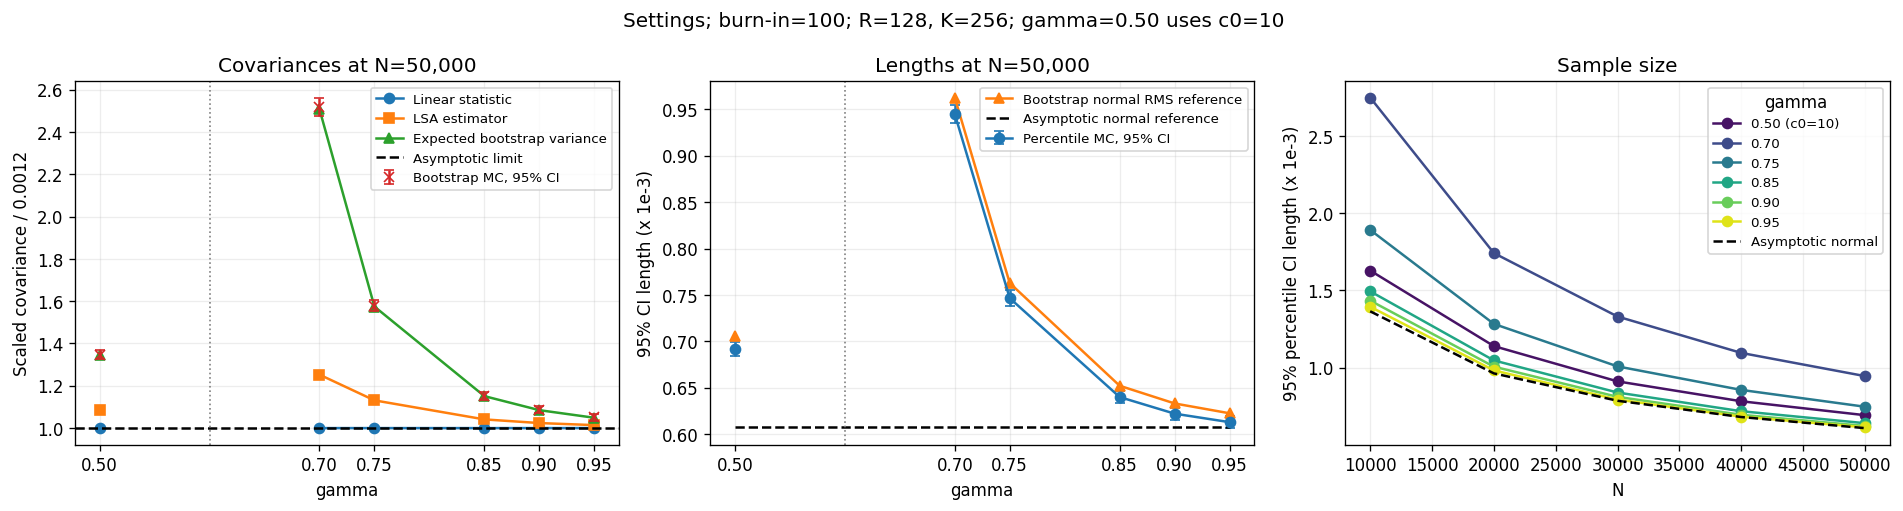

In [9]:
fig,axes=plt.subplots(1,3,figsize=(16,4.3))
last=summary[summary.N==50000].sort_values('gamma')
x=last.gamma.to_numpy()
main=last[last.gamma>=.7]
xm=main.gamma.to_numpy()
axes[0].plot(xm,main.linear_exact/S_INF,'o-',label='Linear statistic')
axes[0].plot(x[:1],last.linear_exact.iloc[:1]/S_INF,'o',color='C0')
axes[0].plot(xm,main.true_exact/S_INF,'s-',label='LSA estimator')
axes[0].plot(x[:1],last.true_exact.iloc[:1]/S_INF,'s',color='C1')
axes[0].plot(xm,main.boot_exact/S_INF,'^-',label='Expected bootstrap variance')
axes[0].plot(x[:1],last.boot_exact.iloc[:1]/S_INF,'^',color='C2')
axes[0].errorbar(x,last.boot_mc/S_INF,yerr=tcrit*last.boot_mc_se/S_INF,
                 fmt='x',capsize=3,label='Bootstrap MC, 95% CI')
axes[0].axhline(1,color='k',ls='--',label='Asymptotic limit')
axes[0].set(xlabel='gamma',ylabel='Scaled covariance / 0.0012',title='Covariances at N=50,000')
axes[0].legend(fontsize=8)
axes[1].errorbar(xm,1e3*main.length_percentile,yerr=1e3*tcrit*main.length_mc_se,
                fmt='o-',capsize=3,label='Percentile MC, 95% CI')
axes[1].errorbar(x[:1],1e3*last.length_percentile.iloc[:1],
                yerr=1e3*tcrit*last.length_mc_se.iloc[:1],fmt='o',capsize=3,color='C0')
axes[1].plot(xm,1e3*main.length_boot_rms_normal,'^-',label='Bootstrap normal RMS reference')
axes[1].plot(x[:1],1e3*last.length_boot_rms_normal.iloc[:1],'^',color='C1')
axes[1].plot(x,1e3*last.length_asym,'k--',label='Asymptotic normal reference')
axes[1].set(xlabel='gamma',ylabel='95% CI length (x 1e-3)',title='Lengths at N=50,000')
axes[1].legend(fontsize=8)
for ax in axes[:2]:
    ax.set_xticks(GAMMAS)
    ax.axvline(.6,color='grey',ls=':',lw=1)
for gi,g in enumerate(GAMMAS):
    a=summary[summary.gamma==g]
    axes[2].plot(a.N,1e3*a.length_percentile,'o-',color=COLORS[gi],
                 label=f'{g:.2f}'+(' (c0=10)' if gi==0 else ''))
axes[2].plot(CHECKPOINTS,1e3*exact[exact.gamma==.95].length_asym,'k--',label='Asymptotic normal')
axes[2].set(xlabel='N',ylabel='95% percentile CI length (x 1e-3)',title='Sample size')
axes[2].legend(title='gamma',fontsize=8)
fig.suptitle(f'Settings; burn-in={BURN}; R={R}, K={K}; gamma=0.50 uses c0=10')
fig.tight_layout()
savefig(fig,'01_covariance_and_lengths')

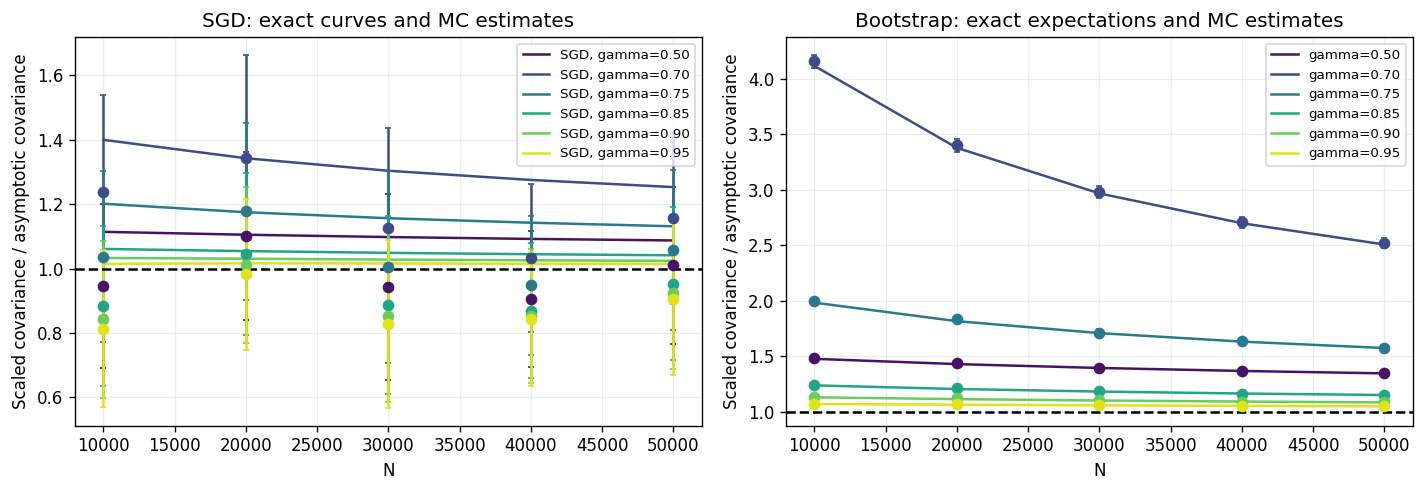

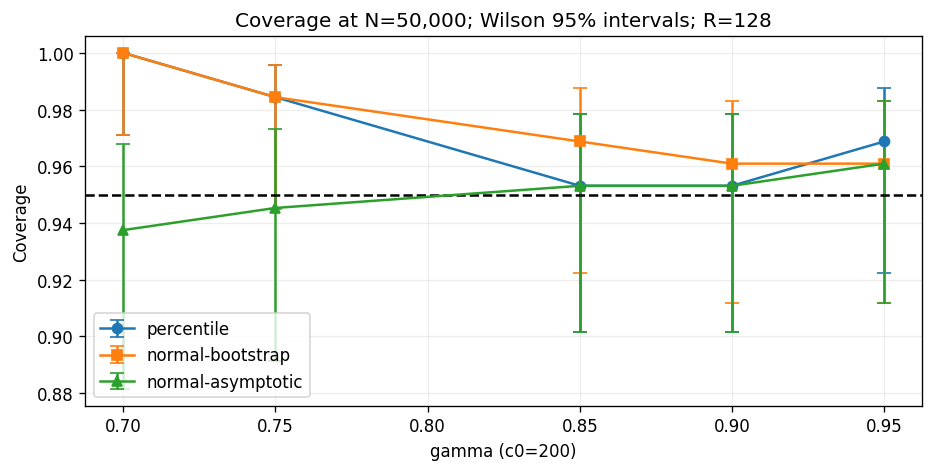

In [10]:
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
for gi,g in enumerate(GAMMAS):
    a=summary[summary.gamma==g]
    axes[0].plot(a.N,a.true_exact/S_INF,'-',color=COLORS[gi],label=f'SGD, gamma={g:.2f}')
    axes[0].errorbar(a.N,a.true_mc/S_INF,yerr=tcrit*a.true_mc_se/S_INF,
                     fmt='o',color=COLORS[gi],capsize=2)
    axes[1].plot(a.N,a.boot_exact/S_INF,'-',color=COLORS[gi],label=f'gamma={g:.2f}')
    axes[1].errorbar(a.N,a.boot_mc/S_INF,yerr=tcrit*a.boot_mc_se/S_INF,
                     fmt='o',color=COLORS[gi],capsize=2)
for ax,title in zip(axes,['SGD: exact curves and MC estimates','Bootstrap: exact expectations and MC estimates']):
    ax.axhline(1,color='k',ls='--')
    ax.set(xlabel='N',ylabel='Scaled covariance / asymptotic covariance',title=title)
    ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig,'02_monte_carlo_validation')

fig,ax=plt.subplots(figsize=(9,4))
for method,marker in [('percentile','o'),('normal-bootstrap','s'),('normal-asymptotic','^')]:
    a=coverage[(coverage.N==50000)&(coverage.gamma>=.7)&(coverage.method==method)].sort_values('gamma')
    ax.errorbar(a.gamma,a.coverage,yerr=np.vstack([a.coverage-a.low,a.high-a.coverage]),
                fmt=marker+'-',capsize=4,label=method)
ax.axhline(.95,color='k',ls='--')
ax.set(xlabel='gamma (c0=200)',ylabel='Coverage',title=f'Coverage at N=50,000; Wilson 95% intervals; R={R}')
ax.legend(); savefig(fig,'03_coverage')

## Longer runs

Extend the exact moment calculations to ten million updates. Plot the estimator variance, bootstrap variance and their corrections to the linear approximation.

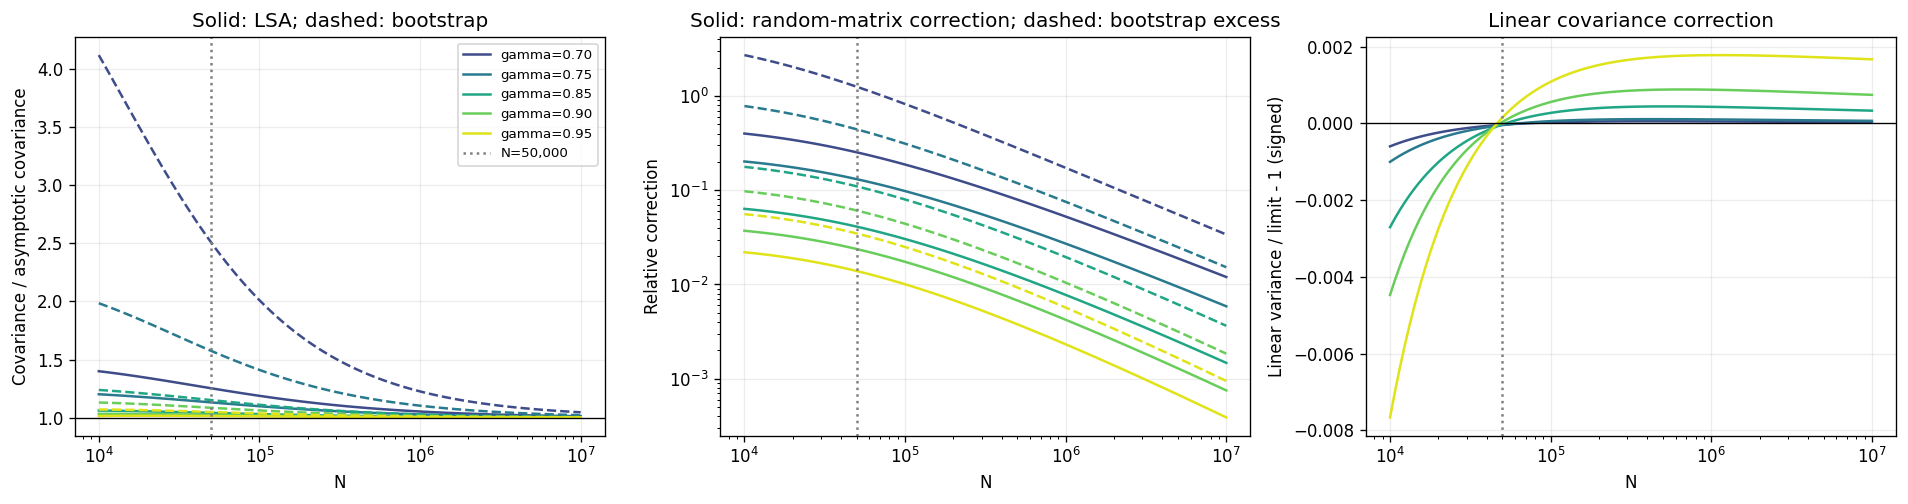

,gamma,N,linear_ratio,true_ratio,bootstrap_ratio
27,0.50,50000,0.999768,1.087166,1.346312
103,0.50,10000000,1.000021,1.009899,1.034750
131,0.70,50000,0.999964,1.252709,2.507991
207,0.70,10000000,1.000029,1.012028,1.045953
235,0.75,50000,0.999953,1.131133,1.574628
311,0.75,10000000,1.000065,1.005931,1.021168
339,0.85,50000,0.999970,1.041084,1.151102
415,0.85,10000000,1.000330,1.001802,1.005445
443,0.90,50000,1.000034,1.023809,1.084760
519,0.90,10000000,1.000742,1.001493,1.003335


In [11]:
long_N=np.unique(np.r_[np.geomspace(10000,LONG_MAX,100).astype(np.int64),CHECKPOINTS])
long_exact=exact_grid(long_N)
long_exact.to_csv(OUT/'long_horizon_exact.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(16,4.3))
for gi,g in enumerate(GAMMAS):
    if g<.7:
        continue
    a=long_exact[long_exact.gamma==g]
    color=COLORS[gi]
    axes[0].semilogx(a.N,a.true_ratio,color=color,label=f'gamma={g:.2f}')
    axes[0].semilogx(a.N,a.bootstrap_ratio,color=color,ls='--')
    axes[1].loglog(a.N,(a.true-a.linear)/S_INF,color=color)
    axes[1].loglog(a.N,(a.bootstrap_exact-a.true)/S_INF,color=color,ls='--')
    axes[2].semilogx(a.N,a.linear_ratio-1,color=color)
for ax in axes:
    ax.axvline(50000,color='grey',ls=':',label='N=50,000' if ax==axes[0] else None)
    ax.set_xlabel('N')
axes[0].axhline(1,color='k',lw=.8)
axes[0].set(ylabel='Covariance / asymptotic covariance',title='Solid: LSA; dashed: bootstrap')
axes[0].legend(fontsize=8)
axes[1].set(ylabel='Relative correction',title='Solid: random-matrix correction; dashed: bootstrap excess')
axes[2].axhline(0,color='k',lw=.8)
axes[2].set(ylabel='Linear variance / limit - 1 (signed)',title='Linear covariance correction')
fig.tight_layout(); savefig(fig,'04_long_horizons')
display(long_exact[long_exact.N.isin([50000,LONG_MAX])][['gamma','N','linear_ratio','true_ratio','bootstrap_ratio']])

### Averaging without burn-in

Repeat the linear variance calculation using all iterates from 0 to n-1, with no extra step-index shift.

In [12]:
full_average_rows=[]
for g,c0 in zip(GAMMAS,C0S):
    for n in [10000,50000,1000000,LONG_MAX]:
        scalar=exact_moments(g,c0,np.array([n-1]),0,0,D,SIGMA,K0)[0,0]
        full_average_rows.append(dict(gamma=g,c0=c0,n=n,Sigma_n_scalar=scalar,ratio=scalar/S_INF,
                               signed_relative_error=scalar/S_INF-1))
full_average_sigma=pd.DataFrame(full_average_rows)
full_average_sigma.to_csv(OUT/'full_average_covariance.csv',index=False)
display(full_average_sigma[full_average_sigma.n==50000])
small=exact_moments(.9,200.,np.array([29]),0,0,D,SIGMA,K0)[0,0]
assert np.isclose(small,direct_linear_variance(29,.9,200.,0,0),rtol=1e-11)

,gamma,c0,n,Sigma_n_scalar,ratio,signed_relative_error
1,0.50,10.0,50000,0.001199,0.999553,-0.000447
5,0.70,200.0,50000,0.001200,0.999882,-0.000118
9,0.75,200.0,50000,0.001200,0.999823,-0.000177
13,0.85,200.0,50000,0.001200,0.999630,-0.000370
17,0.90,200.0,50000,0.001199,0.999491,-0.000509
21,0.95,200.0,50000,0.001199,0.999337,-0.000663


## Save results

Save run settings and package versions alongside the generated tables, arrays and figures.

In [13]:
metadata={
    'profile':PROFILE,'R':R,'K':K,'seed':SEED,'d':D,'sigma':SIGMA,'k0':K0,
    'burn_in':BURN,'step_index_offset':OFFSET,'checkpoints':CHECKPOINTS.tolist(),
    'long_max':LONG_MAX,'gammas':GAMMAS.tolist(),'c0s':C0S.tolist(),
    'projection':u.tolist(),'theta_initial':'theta_star (oracle)',
    'theta_star':THETA_STAR.tolist(),
    'multiplier':'1+sqrt(20)*(Beta(2,2)-0.5), exact rejection sampling',
    'quantiles':'numpy linear interpolation; .025 and .975',
    'bootstrap_covariance_ddof':1,
    'versions':{'python':sys.version,'numpy':np.__version__,'scipy':scipy.__version__,
                'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'numba':numba.__version__},
    'platform':platform.platform(),
}
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False),encoding='utf-8')
(OUT/'requirements.txt').write_text('numpy>=2.0\nscipy>=1.12\npandas>=2.0\nmatplotlib>=3.8\nnumba>=0.61\nipykernel>=6\n',encoding='utf-8')
print('Results saved in',OUT.resolve())
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(p.name, p.stat().st_size, 'bytes')

Results saved in /workspace/lsa_results
01_covariance_and_lengths.pdf 28243 bytes
01_covariance_and_lengths.png 278709 bytes
02_monte_carlo_validation.pdf 24194 bytes
02_monte_carlo_validation.png 170438 bytes
03_coverage.pdf 16967 bytes
03_coverage.png 88084 bytes
04_long_horizons.pdf 40734 bytes
04_long_horizons.png 296113 bytes
covariance_matrices.npz 8491 bytes
coverage.csv 10977 bytes
exact_covariances.csv 6413 bytes
full_average_covariance.csv 1991 bytes
long_horizon_exact.csv 132680 bytes
monte_carlo_raw.npz 853899 bytes
paired_length_differences.csv 459 bytes
requirements.txt 76 bytes
run_metadata.json 1101 bytes
simulation_summary.csv 15986 bytes
